# Welche Gene schaltet eine Maus an, wenn sie Milch macht?

Die **Milchdrüse** verändert sich enorm in der Schwangerschaft und wenn die Mutter ihre Jungen säugt (**Laktation**). Sie besteht aus zwei Arten von Zellen:

* **luminale Zellen** kleiden die Milchgänge innen aus und **produzieren** während der Laktation **die Milch**,
* **basale Zellen** sitzen außen herum und **pressen** die Milch heraus, wie ein Muskel.

Forschende (Fu et al. 2015) haben beide Zelltypen aus Mäusen in drei Zuständen entnommen: **virgin** (jungfräulich, nie trächtig), **pregnant** (trächtig) und **lactating** (säugend), mit zwei Mäusen pro Kombination. Die RNA dieser **12 Proben** wurde sequenziert.

### Unsere Forschungsfrage

> Welche Gene schalten die **luminalen Zellen** an (oder aus), wenn sie von der **Trächtigkeit** zur **Milchproduktion** übergehen? Können wir aus diesen Genen erklären, woraus Milch besteht?

### Der Plan

```mermaid
flowchart LR
    A[1 Daten<br>ansehen] --> B[2 Gruppen<br>festlegen] --> C[3 Vorbereiten:<br>filtern, normalisieren] --> D[4 Design und<br>Kontraste] --> E[5 Testen<br>mit limma] --> F[6 Deuten]
```

Führe die Zellen der Reihe nach von oben aus, mit **Umschalt + Enter**.

In [1]:
setLanguage("de")   # Sprache der Ausgaben und Grafiken

Sprache: Deutsch



## 1 Die Daten ansehen

`loadDataset` lädt die Daten. Sie bestehen aus drei Tabellen: `samples` (was jede Probe ist), `counts` (die Reads) und `genes` (Gennamen). Sehen wir uns zuerst die Proben an.

In [2]:
data <- loadDataset("milk")
data$samples

Datensatz 'milk' geladen: 27179 Gene, 12 Proben.



,sample,celltype,state
,<chr>,<fct>,<fct>
MCL1-DG,MCL1-DG,basal,virgin
MCL1-DH,MCL1-DH,basal,virgin
MCL1-DI,MCL1-DI,basal,pregnant
MCL1-DJ,MCL1-DJ,basal,pregnant
MCL1-DK,MCL1-DK,basal,lactating
MCL1-DL,MCL1-DL,basal,lactating
MCL1-LA,MCL1-LA,luminal,virgin
MCL1-LB,MCL1-LB,luminal,virgin
MCL1-LC,MCL1-LC,luminal,pregnant


Jede Probe hat einen Namen (`MCL1-DG` …), einen Zelltyp (`celltype`) und einen Zustand (`state`). Die Einträge in der Tabelle sind englisch: `lactating` heißt „säugend“, `pregnant` „trächtig“, `virgin` „jungfräulich“.

Jetzt die Counts. `head()` zeigt nur die ersten 6 Zeilen; die ganze Tabelle ist viel länger.

In [3]:
head(data$counts)

,MCL1-DG,MCL1-DH,MCL1-DI,MCL1-DJ,MCL1-DK,MCL1-DL,MCL1-LA,MCL1-LB,MCL1-LC,MCL1-LD,MCL1-LE,MCL1-LF
497097,438,300,65,237,354,287,0,0,0,0,0,0
100503874,1,0,1,1,0,4,0,0,0,0,0,0
100038431,0,0,0,0,0,0,0,0,0,0,0,0
19888,1,1,0,0,0,0,10,3,10,2,0,0
20671,106,182,82,105,43,82,16,25,18,8,3,10
27395,309,234,337,300,290,270,560,464,489,328,307,342


Jede **Zeile** ist ein Gen (die Zahlen links sind Gen-IDs aus der NCBI-Datenbank), jede **Spalte** eine Probe, und jede Zahl sagt, wie viele Reads dieses Gens in dieser Probe gefunden wurden. Die Tabelle `genes` übersetzt die IDs in Gennamen:

In [4]:
head(data$genes)

,gene_id,symbol,description
,<int>,<chr>,<chr>
497097,497097,Xkr4,X-linked Kx blood group related 4
100503874,100503874,Gm19938,"predicted gene, 19938"
100038431,100038431,Gm10568,predicted gene 10568
19888,19888,Rp1,retinitis pigmentosa 1 (human)
20671,20671,Sox17,SRY (sex determining region Y)-box 17
27395,27395,Mrpl15,mitochondrial ribosomal protein L15


**Aufgabe:** Wie viele Gene und wie viele Proben enthält die Zähltabelle? `dim()` gibt die Größe einer Tabelle an: zuerst die Zahl der Zeilen, dann der Spalten.

In [5]:
dim(data$counts)

[1] 27179    12

✅ **Antwort:** **27.179 Gene** (Zeilen) und **12 Proben** (Spalten): 2 Zelltypen × 3 Zustände × 2 Mäuse.

Für die Analyse packen wir die drei Tabellen in einen Behälter, eine `DGEList` aus dem Paket **edgeR**. Sie zählt auch die Reads jeder Probe zusammen: die **Bibliotheksgröße** (library size).

In [6]:
dge <- DGEList(counts = data$counts, samples = data$samples, genes = data$genes)
dge$samples

,group,lib.size,norm.factors,sample,celltype,state
,<fct>,<dbl>,<dbl>,<chr>,<fct>,<fct>
MCL1-DG,1,23227641,1,MCL1-DG,basal,virgin
MCL1-DH,1,21777891,1,MCL1-DH,basal,virgin
MCL1-DI,1,24100765,1,MCL1-DI,basal,pregnant
MCL1-DJ,1,22665371,1,MCL1-DJ,basal,pregnant
MCL1-DK,1,21529331,1,MCL1-DK,basal,lactating
MCL1-DL,1,20015386,1,MCL1-DL,basal,lactating
MCL1-LA,1,20392113,1,MCL1-LA,luminal,virgin
MCL1-LB,1,21708152,1,MCL1-LB,luminal,virgin
MCL1-LC,1,22241607,1,MCL1-LC,luminal,pregnant


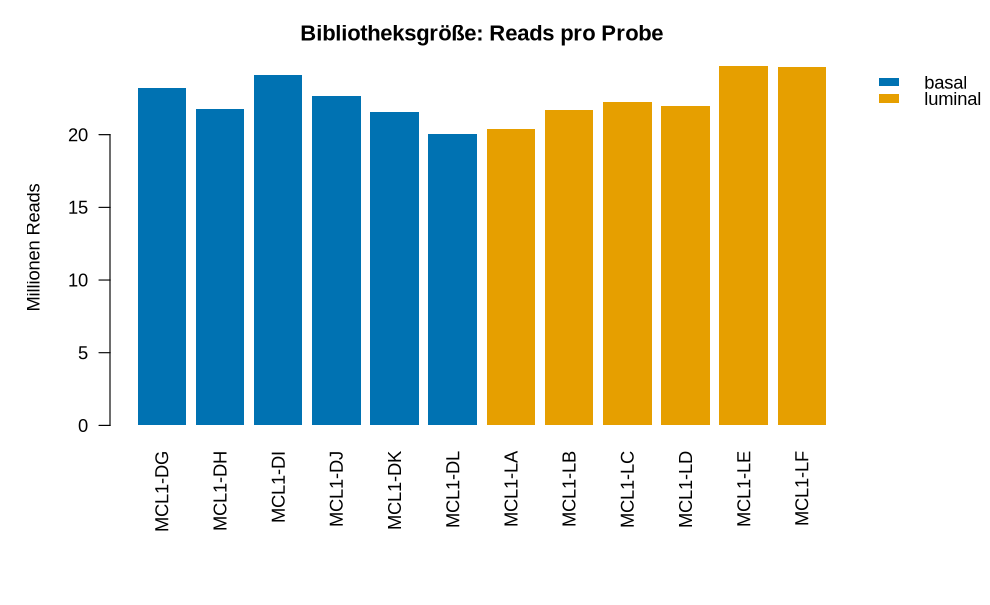

In [7]:
plotLibrarySizes(dge, colour_by = "celltype")

**Frage:** Haben alle Proben gleich viele Reads? Warum wäre es falsch, die rohen Counts eines Gens zwischen zwei Proben zu vergleichen?

✅ **Antwort:** Nein: zwischen etwa **20 und 25 Millionen** Reads. Eine Probe mit 25 Millionen Reads hat für *jedes* Gen etwa 25 % mehr Reads als eine mit 20 Millionen, auch wenn die Zellen identisch sind. Wir müssen also **Anteile** (Reads pro Million) vergleichen, nicht rohe Counts.

**Aufgabe:** Viele Gene werden in diesen Zellen gar nicht benutzt. Wie viele Gene haben **0 Reads in allen 12 Proben**? `rowSums()` addiert jede Zeile, und `sum(... == x)` zählt, wie oft etwas gleich `x` ist.

In [8]:
sum(rowSums(dge$counts) == 0)

[1] 5787

✅ **Antwort:** **5.787 Gene** haben keinen einzigen Read. Die Zellen der Milchdrüse benutzen sie einfach nicht (zum Beispiel Gene, die nur im Gehirn oder in der Leber gebraucht werden).

## 2 Die Gruppen festlegen

Zum Vergleichen muss limma wissen, welche Proben zusammengehören. Jede Kombination aus Zelltyp und Zustand ist eine **Gruppe**, zum Beispiel `luminal_lactating`. Wir kleben die beiden Spalten mit `paste` zusammen und speichern das Ergebnis in der Spalte `group`.

In [9]:
group <- paste(dge$samples$celltype, dge$samples$state, sep = "_")
dge$samples$group <- factor(group, levels = unique(group))
table(dge$samples$group)


     basal_virgin    basal_pregnant   basal_lactating    luminal_virgin  luminal_pregnant luminal_lactating 
                2                 2                 2                 2                 2                 2 

**Frage:** Wie viele Proben hat jede Gruppe? Warum benutzen Forschende mehrere Mäuse pro Gruppe (**Replikate**) statt nur einer?

✅ **Antwort:** **6 Gruppen mit je 2 Proben.** Mit nur einer Maus pro Gruppe könnten wir nicht unterscheiden, ob ein Unterschied von der Bedingung kommt oder nur daher, dass jede Maus etwas anders ist. Replikate zeigen, wie groß diese natürliche Schwankung ist; limma vergleicht jeden Unterschied damit.

Sehen wir uns ein einzelnes Gen an. **Csn2** ist das Gen für **β-Casein**, das wichtigste Protein in der Milch. `plotGene` zeigt seine Expression in jeder Probe als **log2 Counts pro Million**: 1 höher bedeutet doppelt so viel. Wo erwartest du es hoch?

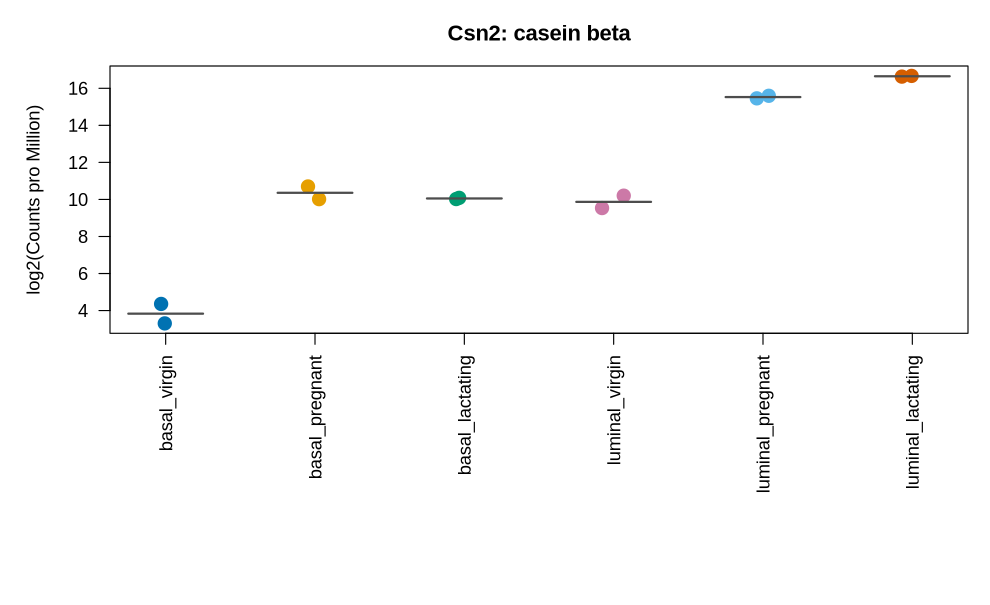

In [10]:
plotGene(dge, "Csn2", group_by = "group")

**Aufgabe:** Prüfe mit deinem Biologiewissen, ob die Proben richtig beschriftet sind. **Krt5** (Keratin 5) ist ein typisches Protein der basalen Zellen, **Krt8** (Keratin 8) der luminalen Zellen. Zeichne eins davon.

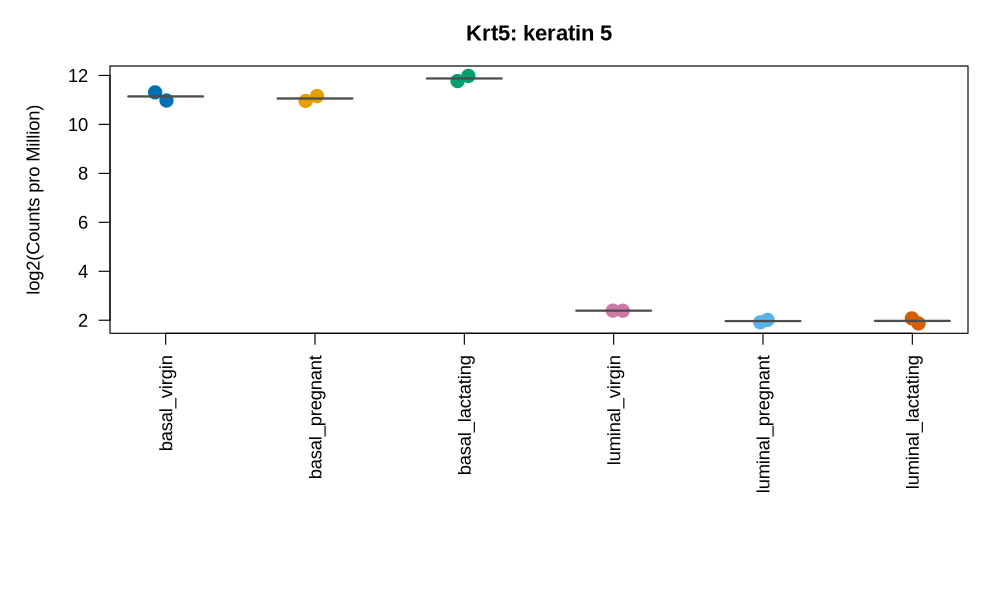

In [11]:
plotGene(dge, "Krt5", group_by = "group")

✅ **Antwort:** Csn2 ist bei jungfräulichen Mäusen niedrig, in der Trächtigkeit viel höher und am höchsten in **säugenden luminalen Zellen** (etwa 2¹³ ≈ 8.000-mal mehr als in basalen Zellen jungfräulicher Mäuse!). Krt5 ist in allen **basalen** Proben hoch und in luminalen niedrig (Krt8 umgekehrt). Die Beschriftung passt also.

## 3 Die Daten vorbereiten

### Filtern

Gene mit nur einer Handvoll Reads lassen sich nicht zuverlässig testen: 0 gegen 2 Reads könnte gut Zufall sein. `filterByExpr` behält nur Gene, die genug Reads in mindestens so vielen Proben haben, wie die kleinste Gruppe hat (hier 2). `TRUE` heißt behalten.

In [12]:
keep <- filterByExpr(dge)
table(keep)

keep
FALSE  TRUE 
11210 15969 

In [13]:
dge <- dge[keep, , keep.lib.sizes = FALSE]
dim(dge)

[1] 15969    12

### Normalisieren

Jetzt sehen wir uns die Verteilung **aller** Gene in jeder Probe an. Jeder Kasten zeigt die mittlere Hälfte der Gene; der Strich im Kasten ist der Median. Wenn die Proben vergleichbar sind, sollten die Kästen etwa gleich hoch liegen.

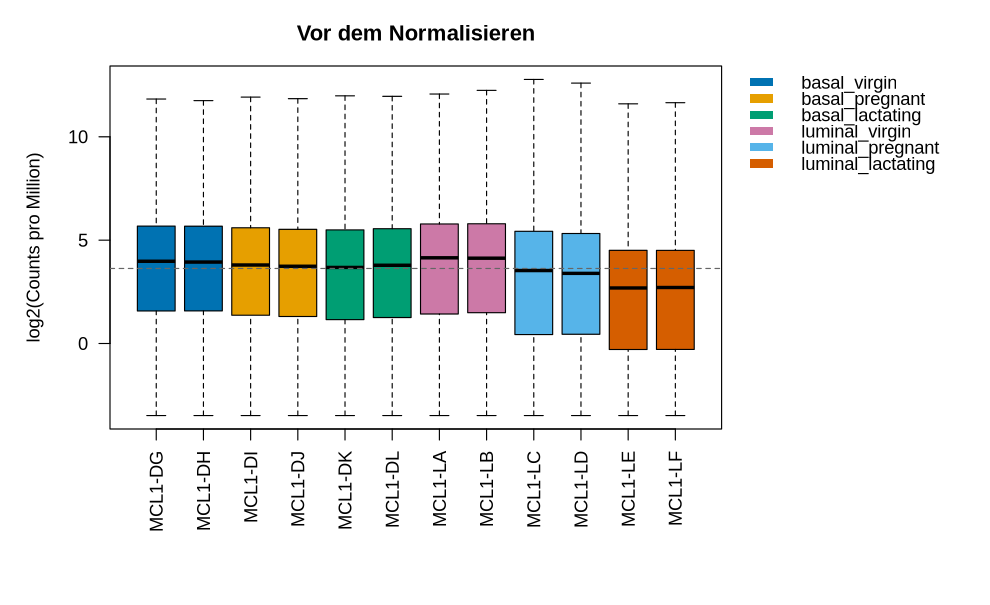

In [14]:
plotDistributions(dge, colour_by = "group", title = "Vor dem Normalisieren")

Sieh dir die beiden säugenden luminalen Proben an (`MCL1-LE`, `MCL1-LF`): Ihre Kästen liegen **tiefer**. Sind wirklich alle ihre Gene weniger aktiv? Nein! Diese Zellen stecken einen riesigen Teil ihrer RNA in ein paar Milchgene. Berechne den Anteil der Reads, den allein Csn2 (Gen-ID 12991) in der Probe `MCL1-LE` hat:

In [15]:
data$counts["12991", "MCL1-LE"] / sum(data$counts[, "MCL1-LE"])   # Anteil an allen Reads

[1] 0.1041865

Etwa **10 %** aller Reads stammen von diesem einen Gen. Dann bleiben für alle anderen Gene weniger Reads übrig, und sie *sehen* niedriger aus. Die **TMM-Normalisierung** in `normLibSizes` gleicht das aus: Sie berechnet für jede Probe einen Korrekturfaktor (`norm.factors`) aus den vielen Genen, die sich nicht verändern.

In [16]:
dge <- normLibSizes(dge)
dge$samples[, c("group", "lib.size", "norm.factors")]

,group,lib.size,norm.factors
,<fct>,<dbl>,<dbl>
MCL1-DG,basal_virgin,23219195,1.2384285
MCL1-DH,basal_virgin,21769326,1.2137919
MCL1-DI,basal_pregnant,24092719,1.1248001
MCL1-DJ,basal_pregnant,22657703,1.0711828
MCL1-DK,basal_lactating,21522881,1.0362789
MCL1-DL,basal_lactating,20009184,1.0869418
MCL1-LA,luminal_virgin,20385437,1.3681957
MCL1-LB,luminal_virgin,21699830,1.3649435
MCL1-LC,luminal_pregnant,22236469,1.0039770


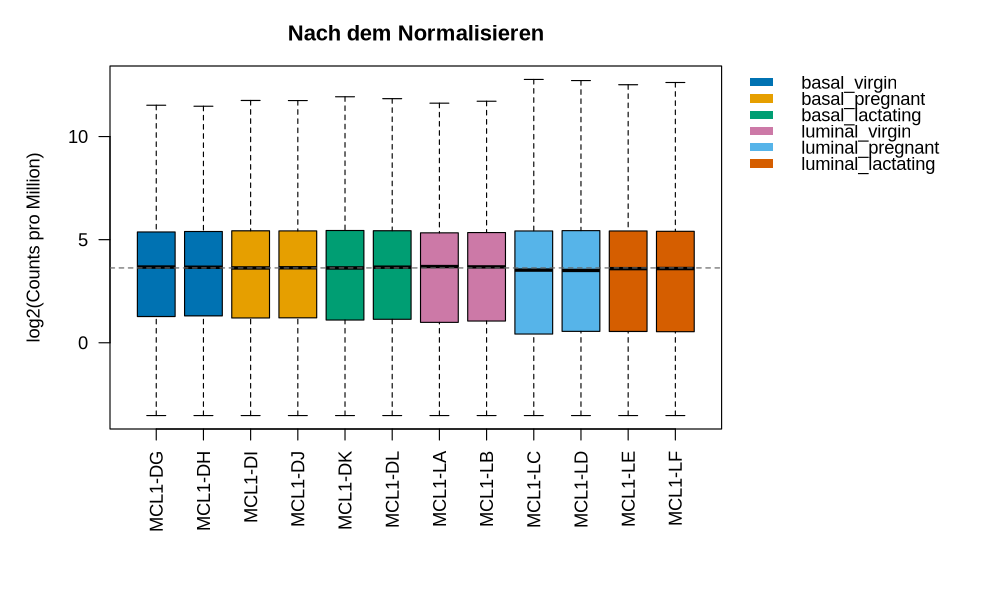

In [17]:
plotDistributions(dge, colour_by = "group", title = "Nach dem Normalisieren")

**Frage:** Wie viele Gene bleiben nach dem Filtern übrig? Welche Proben bekommen den kleinsten Korrekturfaktor, und was hat sich im Kastendiagramm verändert?

✅ **Antwort:** **15.969 Gene** von 27.179 bleiben übrig. Die säugenden luminalen Proben LE und LF bekommen den kleinsten Faktor (etwa **0,53**): Ihre Bibliotheksgröße wird praktisch halbiert, um die Reads der Milchgene auszugleichen. Nach dem Normalisieren liegen alle Kästen etwa gleich hoch.

### Die Probenkarte (MDS)

Bevor wir einzelne Gene testen, sehen wir uns an, wie ähnlich sich die Proben **insgesamt** sind. Ein **MDS-Plot** setzt jede Probe auf eine Karte: Proben, deren ~16.000 Gene ähnlich exprimiert sind, liegen nah beieinander. **Richtung 1** (links–rechts) ist die Richtung, in der sich die Proben am stärksten unterscheiden; die Prozentzahl sagt, wie viel aller Unterschiede sie zeigt.

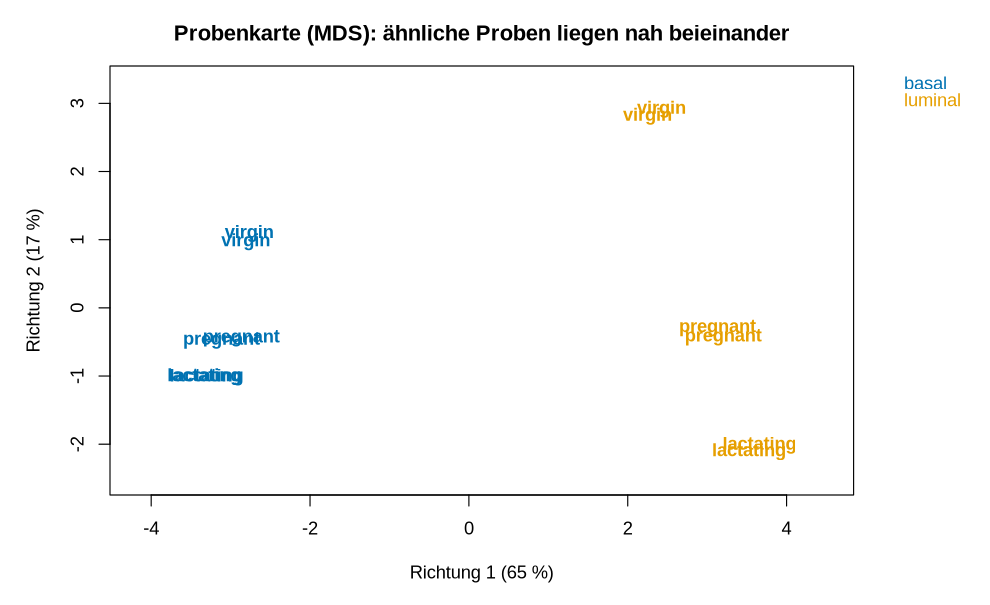

In [18]:
plotSamples(dge, colour_by = "celltype", label_by = "state")

**Aufgabe:** Färbe die Proben jetzt nach Zustand ein und beschrifte sie mit dem Zelltyp.

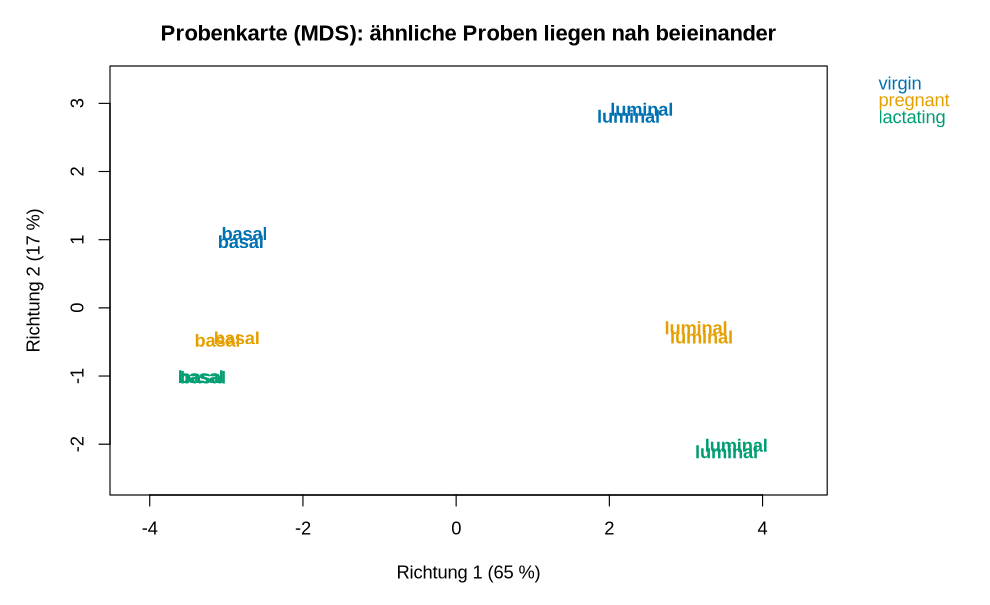

In [19]:
plotSamples(dge, colour_by = "state", label_by = "celltype")

**Frage:** Was trennt die Proben entlang Richtung 1, was entlang Richtung 2? Liegen die beiden Replikate jeder Gruppe nah beieinander? Warum ist das eine gute Nachricht?

✅ **Antwort:** Richtung 1 (**65 %**) trennt **basale von luminalen** Zellen: Der Zelltyp ist mit Abstand der größte Unterschied. Richtung 2 (**17 %**) sortiert die Proben nach Zustand: jungfräulich → trächtig → säugend, und die Veränderung ist in luminalen Zellen größer. Die Replikate liegen nah beieinander, das Experiment hat also gut funktioniert und keine Proben wurden vertauscht.

## 4 Design und Kontraste

### Die Design-Matrix

Die **Design-Matrix** sagt limma, zu welcher Gruppe jede Probe gehört: eine Spalte pro Gruppe, mit einer 1, wenn die Probe dazugehört.

In [20]:
design <- model.matrix(~0 + group, data = dge$samples)
colnames(design) <- levels(dge$samples$group)
design

,basal_virgin,basal_pregnant,basal_lactating,luminal_virgin,luminal_pregnant,luminal_lactating
MCL1-DG,1,0,0,0,0,0
MCL1-DH,1,0,0,0,0,0
MCL1-DI,0,1,0,0,0,0
MCL1-DJ,0,1,0,0,0,0
MCL1-DK,0,0,1,0,0,0
MCL1-DL,0,0,1,0,0,0
MCL1-LA,0,0,0,1,0,0
MCL1-LB,0,0,0,1,0,0
MCL1-LC,0,0,0,0,1,0
MCL1-LD,0,0,0,0,1,0


### Kontraste: Welche Gruppen vergleichen wir?

Ein **Kontrast** ist der Vergleich, der dich interessiert, geschrieben als Subtraktion: `A - B` fragt „wie unterscheidet sich A von B?“. Ein **positiver** log Fold Change bedeutet dann **höher in A**.

Unsere Frage vergleicht **säugende** mit **trächtigen** luminalen Zellen. Warum nicht einfach alle säugenden mit allen trächtigen Proben? Weil basale Zellen keine Milch machen, und wenn wir sie mischen, verwischt das Ergebnis: Der MDS-Plot hat gezeigt, dass der Zelltyp der größte Unterschied von allen ist.

**Aufgabe:** Fülle die beiden Kontraste aus:
1. `lactating_vs_pregnant`: luminale Zellen, säugend verglichen mit trächtig,
2. `luminal_vs_basal`: bei jungfräulichen Mäusen, luminale verglichen mit basalen Zellen.

Benutze die Gruppennamen genau so wie in der Design-Matrix.

In [21]:
contrasts <- makeContrasts(
    lactating_vs_pregnant = luminal_lactating - luminal_pregnant,
    luminal_vs_basal      = luminal_virgin - basal_virgin,
    levels = design)
contrasts

,lactating_vs_pregnant,luminal_vs_basal
basal_virgin,0,-1
basal_pregnant,0,0
basal_lactating,0,0
luminal_virgin,0,1
luminal_pregnant,-1,0
luminal_lactating,1,0


**Frage:** Was bedeutet im Kontrast `lactating_vs_pregnant` ein log Fold Change von **+3** für ein Gen? Und **−1**? Welchen Kontrast würdest du schreiben, um die Gene zu finden, die sich in **basalen** Zellen in der Trächtigkeit verändern?

✅ **Antwort:** **+3**: Das Gen ist in säugenden luminalen Zellen 2³ = **8-mal höher** als in trächtigen. **−1**: Es ist **halb** so hoch. Für basale Zellen in der Trächtigkeit: `basal_pregnant - basal_virgin`.

## 5 Jedes Gen mit limma testen

Drei Schritte:

1. **`voom`** wandelt die Counts in log2 Counts pro Million um und schätzt, wie zuverlässig jeder Wert ist: Gene mit wenigen Reads schwanken stärker und bekommen deshalb weniger Gewicht. Der Plot zeigt das: Je weniger Reads (links), desto größer die Schwankung (oben).
2. **`lmFit`** berechnet für jedes Gen den Mittelwert in jeder Gruppe, und **`contrasts.fit`** die Unterschiede, nach denen wir in den Kontrasten gefragt haben.
3. **`eBayes`** testet, ob jeder Unterschied größer ist als die natürliche Schwankung zwischen den Replikaten. Mit nur 2 Replikaten lässt sich diese Schwankung für ein einzelnes Gen schlecht schätzen, also „leiht“ sich limma Information von allen anderen Genen. Deshalb funktioniert limma auch bei kleinen Experimenten.

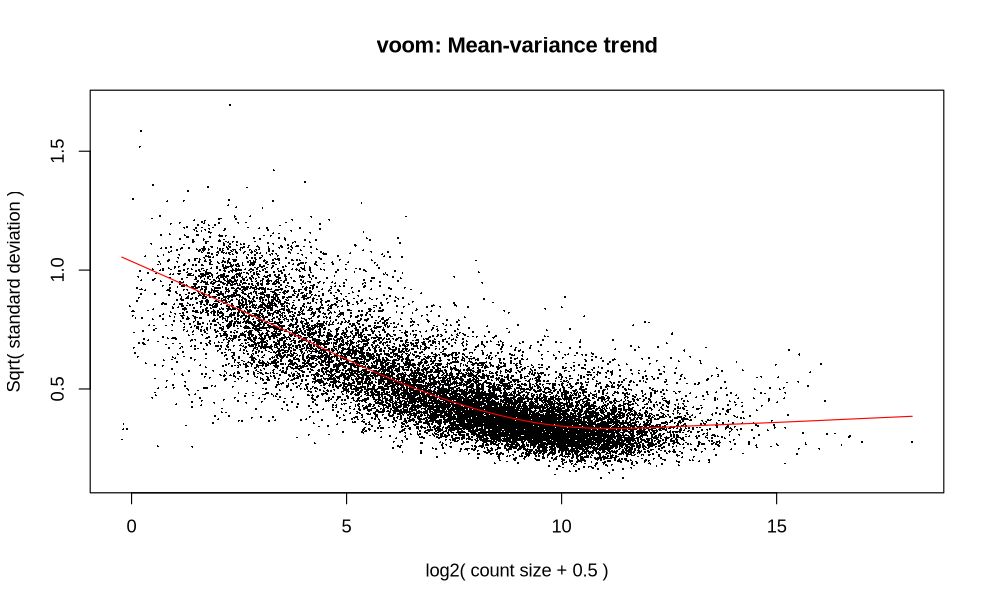

In [22]:
v <- voom(dge, design, plot = TRUE)

In [23]:
fit <- lmFit(v, design)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)

### Wie viele Gene haben sich verändert?

Für jedes Gen berechnet limma einen **p-Wert**: Wie wahrscheinlich ist ein so großer Unterschied, wenn sich das Gen in Wirklichkeit gar nicht verändert hat? Klein = überzeugend.

Aber Vorsicht: Wir testen etwa 16.000 Gene. Mit der üblichen Grenze p < 0,05 würden etwa 5 % der Gene, die sich **nicht** verändern, trotzdem zufällig signifikant aussehen: Das wären 800 falsche Treffer! Deshalb gibt limma auch einen **adjustierten p-Wert** (`adj.P.Val`) an. Nehmen wir alle Gene mit adjustiertem p < 0,05, dann sind nur etwa 5 % **dieser Liste** falsche Treffer.

`decideTests` zählt die Gene mit adjustiertem p < 0,05: hoch (`Up`), runter (`Down`) oder nicht signifikant (`NotSig`).

In [24]:
summary(decideTests(fit))

       lactating_vs_pregnant luminal_vs_basal
Down                    3679             5121
NotSig                  8604             5746
Up                      3686             5102

**Frage:** Wie viele Gene gehen von der Trächtigkeit zur Laktation hoch, wie viele runter? Welcher der beiden Kontraste hat mehr veränderte Gene, und passt das zum MDS-Plot?

✅ **Antwort:** Säugend gegen trächtig: etwa **3.700 hoch** und **3.700 runter**. Luminal gegen basal: etwa **5.100 hoch** und **5.100 runter**, also noch mehr. Das passt zum MDS-Plot, in dem der Zelltyp (Richtung 1) der größte Unterschied war. Tausende signifikante Gene sind bei einer so großen biologischen Veränderung normal; deshalb sehen wir uns im nächsten Schritt die **stärksten** an.

## 6 Die Ergebnisse deuten

### Der Vulkan-Plot

Im **Vulkan-Plot** ist jedes Gen ein Punkt. Links–rechts ist der log Fold Change (links: niedriger beim Säugen, rechts: höher), und nach oben, wie sicher das Ergebnis ist. Die spannendsten Gene sind oben links und oben rechts: eine große Veränderung **und** überzeugend. Farbige Punkte sind signifikant und ändern sich mindestens um das 2-fache (gestrichelte Linien).

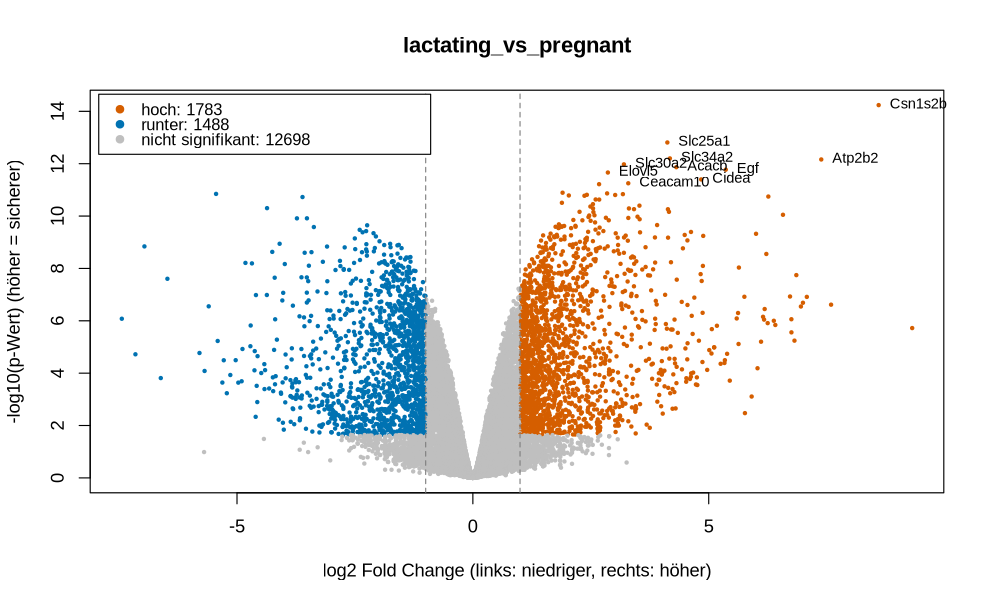

In [25]:
plotVolcano(fit, "lactating_vs_pregnant")

### Die Top-Gene

`showTop` listet die überzeugendsten Gene mit Namen und Beschreibung auf. `change` übersetzt den log Fold Change zurück in „-mal höher/niedriger“.

In [26]:
showTop(fit, "lactating_vs_pregnant", n = 15, direction = "up")

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
Csn1s2b,casein alpha s2-like B,8.60,388.7× höher,3.6,9.2e-11
Slc25a1,solute carrier family 25 (mitochondrial car…,4.12,17.4× höher,5.8,1.2e-09
Slc34a2,solute carrier family 34 (sodium phosphate)…,4.18,18.1× höher,4.3,2.8e-09
Atp2b2,"ATPase, Ca++ transporting, plasma membrane 2",7.39,167.2× höher,1.3,2.8e-09
Slc30a2,solute carrier family 30 (zinc transporter)…,3.20,9.2× höher,2.7,3.4e-09
Acacb,acetyl-Coenzyme A carboxylase beta,4.31,19.9× höher,4.4,3.6e-09
Egf,epidermal growth factor,5.36,41.1× höher,0.7,3.9e-09
Elovl5,ELOVL fatty acid elongase 5,2.86,7.3× höher,6.5,4.3e-09
Cidea,cell death-inducing DNA fragmentation facto…,4.84,28.6× höher,3.4,7.1e-09


**Aufgabe:** Wähle ein Gen aus der Liste, das dich interessiert, und sieh es dir in allen Gruppen an.

Finde heraus, was es tut: Suche seinen Namen auf [GeneCards](https://www.genecards.org) (für menschliche Gene; das Maus-Gen tut meist dasselbe), [NCBI Gene](https://www.ncbi.nlm.nih.gov/gene) oder [UniProt](https://www.uniprot.org), oder denke über die Beschreibung nach. *Tipp: Milch enthält Eiweiß (Caseine), Fett, Milchzucker (Laktose), Calcium, Zink und Phosphat.*

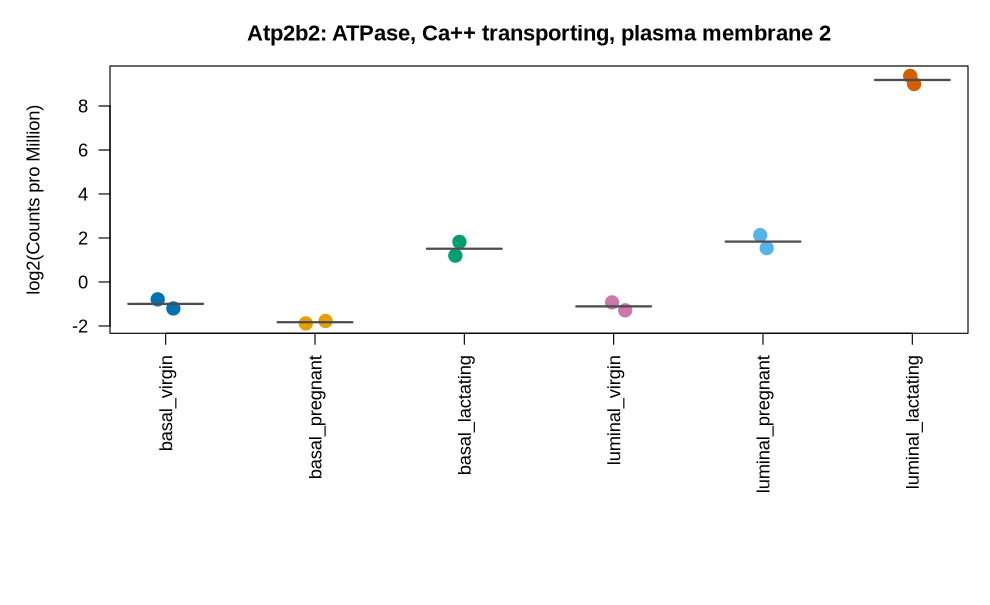

In [27]:
plotGene(dge, "Atp2b2", group_by = "group")

**Frage:** Kannst du die Top-Gene damit verbinden, woraus Milch besteht? Finde mindestens drei Beispiele.

✅ **Antwort:** * **Eiweiß:** *Csn1s2b* ist ein **Casein**, ein Milchprotein (≈ 390-mal höher).
* **Calcium:** *Atp2b2* ist eine Calciumpumpe, die Calcium **in die Milch** befördert (≈ 170-mal höher).
* **Zink und Phosphat:** *Slc30a2* transportiert Zink, *Slc34a2* Phosphat in die Milch.
* **Fett:** *Acacb*, *Elovl5* und *Pmvk* stellen Fettsäuren und andere Fette her; *Cidea* hilft, das Fett in die Tröpfchen zu verpacken, aus denen das Milchfett besteht; *Slc25a1* liefert das Baumaterial für Fettsäuren.

Die luminalen Zellen schalten also eine ganze **Milchfabrik** an: Gene für jeden Bestandteil der Milch.

Wo sind die berühmten Milchgene wie **Wap** (Molkenprotein) und **Lalba** (α-Lactalbumin, wird zur Herstellung von Laktose gebraucht)? Sieh dir eins davon an:

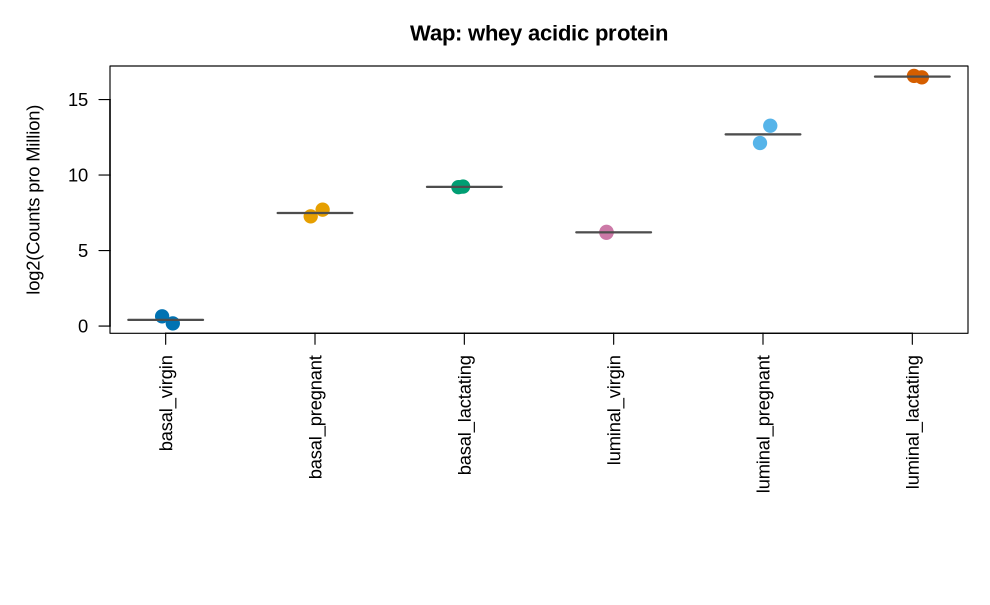

In [28]:
plotGene(dge, "Wap", group_by = "group")

**Frage:** Wap ist in säugenden Zellen signifikant höher, steht aber nicht oben in der Liste. Warum nicht?

✅ **Antwort:** Wap ist schon in der **Trächtigkeit sehr hoch**: Die Drüse bereitet sich vor der Geburt auf die Milchproduktion vor. Von der Trächtigkeit zur Laktation steigt es nur noch etwa 14-fach (logFC ≈ 3,8), weniger als die Top-Gene. Die Liste ist danach sortiert, wie überzeugend die Veränderung ist, nicht danach, wie hoch ein Gen exprimiert ist.

Jetzt die Gene, die **runter** gehen:

In [29]:
showTop(fit, "lactating_vs_pregnant", n = 10, direction = "down")

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
Rbp1,"retinol binding protein 1, cellular",-5.44,43.5× niedriger,6.1,1.4e-08
Ppl,periplakin,-3.61,12.2× niedriger,6.4,1.4e-08
Slc39a4,solute carrier family 39 (zinc transporter)…,-4.36,20.6× niedriger,2.7,2.7e-08
Acot1,acyl-CoA thioesterase 1,-3.52,11.5× niedriger,5.7,4.4e-08
BC006965,cDNA sequence BC006965,-3.73,13.3× niedriger,4.2,4.4e-08
Tbc1d9,"TBC1 domain family, member 9",-2.24,4.7× niedriger,6.3,6.8e-08
Anpep,"alanyl aminopeptidase, membrane",-3.37,10.3× niedriger,6.5,7.0e-08
Sox4,SRY (sex determining region Y)-box 4,-2.40,5.3× niedriger,7.5,8.1e-08
Cldn3,claudin 3,-2.26,4.8× niedriger,5.2,8.8e-08


### Dein Fazit

**Aufgabe:** Beantworte die Forschungsfrage in zwei oder drei Sätzen, so wie in einem Laborbericht: Was hast du verglichen, was hast du gefunden, und was bedeutet es?

✅ **Antwort:** Wir haben luminale Zellen säugender und trächtiger Mäuse (je 2 Mäuse) mit limma verglichen. Etwa 3.700 Gene gingen signifikant hoch und 3.700 runter. Am stärksten stiegen Gene für jeden Bestandteil der Milch: Caseine (Eiweiß), Fettherstellung und Fetttröpfchen sowie Transporter für Calcium, Zink und Phosphat. Zu Beginn der Laktation schalten die luminalen Zellen also ein komplettes Milchproduktionsprogramm an. Unter den Genen, die runter gehen, sind einige für Wachstum und Entwicklung (z. B. *Sox4*): Die Drüse ist fertig gewachsen und konzentriert sich jetzt auf die Milch.

### Bonus: luminale gegen basale Zellen

Sieh dir den zweiten Kontrast an. Welche Gene machen eine basale Zelle zu einer basalen Zelle?

In [30]:
showTop(fit, "luminal_vs_basal", n = 15)

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
Dll1,delta like canonical Notch ligand 1,-6.42,85.8× niedriger,5.9,2.3e-11
Postn,"periostin, osteoblast specific factor",-7.58,191.2× niedriger,7.9,2.3e-11
Col4a2,"collagen, type IV, alpha 2",-5.54,46.5× niedriger,7.6,2.3e-11
Krt5,keratin 5,-8.93,486.1× niedriger,6.7,2.3e-11
Stc2,stanniocalcin 2,5.67,51.0× höher,4.0,5.7e-11
Antxr1,anthrax toxin receptor 1,-7.35,162.9× niedriger,5.7,5.7e-11
Prlr,prolactin receptor,6.62,98.5× höher,5.0,5.9e-11
Aebp1,AE binding protein 1,-5.80,55.7× niedriger,4.8,6.2e-11
Acta2,"actin alpha 2, smooth muscle, aorta",-8.58,383.2× niedriger,8.9,6.2e-11


✅ **Antwort:** Negativer logFC = höher in **basalen** Zellen: *Krt5* (Keratin 5, fast 500-mal höher), Kollagen *Col4a2* und *Postn* (das Bindegewebe um die Milchgänge), *Dll1* (Notch-Signalweg). Positiv = höher in **luminalen** Zellen: *Prlr*, der Rezeptor für das Hormon **Prolaktin**, das den luminalen Zellen das Signal zur Milchproduktion gibt, und *Stc2*.

**Gut gemacht!** 🎉 Du hast eine komplette differenzielle Expressionsanalyse durchgeführt, genau so, wie Forschende es tun. Jetzt bist du dran: Wähle eines der Notebooks `02_diy_…`, `03_diy_…` oder `04_diy_…` und beantworte selbstständig eine neue Forschungsfrage.

## Quellen

**Daten**
* **Milch (Tutorial):** Fu NY, Rios AC, Pal B, et al. (2015). EGF-mediated induction of Mcl-1 at the switch to lactation is essential for alveolar cell survival. *Nature Cell Biology* 17:365–375. [doi:10.1038/ncb3117](https://doi.org/10.1038/ncb3117). Counts aus GEO [GSE60450](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE60450).
* **Dexamethason (airway):** Himes BE, Jiang X, Wagner P, et al. (2014). RNA-Seq transcriptome profiling identifies CRISPLD2 as a glucocorticoid responsive gene that modulates cytokine function in airway smooth muscle cells. *PLoS ONE* 9(6):e99625. [doi:10.1371/journal.pone.0099625](https://doi.org/10.1371/journal.pone.0099625). Counts aus dem Bioconductor-Paket [airway](https://bioconductor.org/packages/airway) (Love M).
* **Pasilla:** Brooks AN, Yang L, Duff MO, et al. (2011). Conservation of an RNA regulatory map between *Drosophila* and mammals. *Genome Research* 21:193–202. [doi:10.1101/gr.108662.110](https://doi.org/10.1101/gr.108662.110). Counts aus dem Bioconductor-Paket [pasilla](https://bioconductor.org/packages/pasilla).
* **Brustkrebs:** The Cancer Genome Atlas Network (2012). Comprehensive molecular portraits of human breast tumours. *Nature* 490:61–70. [doi:10.1038/nature11412](https://doi.org/10.1038/nature11412). Counts (STAR – Counts) von 10 Patientinnen aus TCGA-BRCA, aus den [NCI Genomic Data Commons](https://portal.gdc.cancer.gov).
* **Gennamen:** Bioconductor-Annotationspakete org.Mm.eg.db, org.Hs.eg.db, org.Dm.eg.db (Carlson M).

**Software und Methode**
* **limma:** Ritchie ME, Phipson B, Wu D, et al. (2015). limma powers differential expression analyses for RNA-sequencing and microarray studies. *Nucleic Acids Research* 43(7):e47. [doi:10.1093/nar/gkv007](https://doi.org/10.1093/nar/gkv007)
* **voom:** Law CW, Chen Y, Shi W, Smyth GK (2014). voom: precision weights unlock linear model analysis tools for RNA-seq read counts. *Genome Biology* 15:R29. [doi:10.1186/gb-2014-15-2-r29](https://doi.org/10.1186/gb-2014-15-2-r29)
* **edgeR:** Chen Y, Chen L, Lun ATL, Baldoni PL, Smyth GK (2025). edgeR v4: powerful differential analysis of sequencing data with expanded functionality and improved support for small counts and larger datasets. *Nucleic Acids Research* 53(2):gkaf018. [doi:10.1093/nar/gkaf018](https://doi.org/10.1093/nar/gkaf018)
* **Ablauf, dem dieses Praktikum folgt:** Law CW, Alhamdoosh M, Su S, et al. (2016). RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR. *F1000Research* 5:1408. [doi:10.12688/f1000research.9005.3](https://doi.org/10.12688/f1000research.9005.3)